# UP2 evidence notebook: the 17 counted items (Team M001, Update Presentation 2)

**Live scorecard.** Every cell recomputes its number from data/reports/models on disk (or runs a program) and records the
result in a registry; the **master table at the end** is built from that registry. If an input is missing the cell shows
`missing`/`error` instead of crashing and the item drops to the evidence that remains.

**Read this first (limitations, stated plainly).**
- **Synthetic/simulated data is a coach-approved substitute for rig data** (logistics: the sensor parts may not arrive in time). It is used openly and every number keeps its provenance tag. The hardware (AD7606, IEPE accelerometers, STM32/ESP32-C6) is not built. Every ML number below is
  `[SYNTHETIC]` (generated by `aiengine/synth_v3`); every COE number is `[SIMULATION]`/`[CALCULATED]`/`[MEASURED host]` (this PC, not the STM32).
- Rank = *form* of evidence (ladder: `.claude/rules/evidence-strength.md`). A live-recomputed simulation is Rank 9 "working simulation demo"; it does
  **not** become physical-prototype evidence. The provenance tag says what the data is.
- ME-owned items (C1, C6, S1, S2, S3) and C2 (SELV/IEPE power) are marked **NOT EVIDENCED HERE - evidence to be supplied by owner** and are **not** counted as met. C3 (BOM cost) was **excluded by the reviewer** and is not in the table; the bar is therefore more than 75 % of 17 = **13 items**. Owners add evidence in one place: `up2_helpers.OVERRIDES`.
- Public-data results (PPR v2: XJTU-SY / IMS / MaFaulDa) are shown next to the synthetic ones and still FAIL S7/IS3 on real bearings.

In [1]:
import time, json, platform, os, sys, warnings
T_START = time.time()
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML, Image
import ppr_helpers as P
import up2_helpers as U
P.seed_everything(P.SEED); P.style_matplotlib()
pd.set_option("display.width", 220, "display.max_colwidth", 140, "display.max_rows", 100)
FIG = U.EVIDENCE / "up2_figures"; FIG.mkdir(parents=True, exist_ok=True)
print("git HEAD:", P.git_head(), "| python", sys.version.split()[0], "|", platform.platform(), "|", os.cpu_count(), "CPUs")
print("repo:", U.REPO)
print("dotnet:", P.dotnet_path())

git HEAD: 9a9654a (+uncommitted changes) | python 3.11.9 | Windows-10-10.0.26300-SP0 | 24 CPUs
repo: C:\Users\lenovo\Documents\KFUPM\Term261\ICS414\Repo\DT-up2
dotnet: C:\Program Files\dotnet\dotnet.EXE


## 0. Stored reports this notebook reads (file name and timestamp)

In [2]:
spec_p, spec = U.stored_spec_check()
res_p, resid = U.residual_latest()
coe_p, coe_st = U.coe_stored()
int_p, integ = U.stored_integration()
ppr_int = U.EVIDENCE / "integration_measurements_20261005.md"
public_p = U.REPORTS / "spec_check_20261005T012112Z_real_v2.json"
for k, p in [("UP2 spec check (newest)", spec_p), ("IS2 residual (newest)", res_p), ("COE verification", coe_p),
             ("IS1/S9 measurement (newest)", int_p), ("PPR integration measurements", ppr_int if ppr_int.exists() else None),
             ("PPR public-data result (v2)", public_p if public_p.exists() else None)]:
    print(f"{k:34s}: {U.stamp(p)}")
if spec: print("spec check meta:", {k: spec['meta'].get(k) for k in ('git_commit','git_dirty','seed','utc','command')})

UP2 spec check (newest)           : up2_spec_check_20261024T114947Z.json (file mtime 2026-10-24 14:49)
IS2 residual (newest)             : up2_residual_20261024T173626Z.json (file mtime 2026-10-24 20:36)
COE verification                  : coe_verification.json (file mtime 2026-10-24 04:38)
IS1/S9 measurement (newest)       : integration_measurements_up2_v3b_20261024.md (file mtime 2026-10-24 16:32)
PPR integration measurements      : integration_measurements_20261005.md (file mtime 2026-10-24 04:07)
PPR public-data result (v2)       : spec_check_20261005T012112Z_real_v2.json (file mtime 2026-10-24 04:07)
spec check meta: {'git_commit': 'de29ad0', 'git_dirty': False, 'seed': 20261004, 'utc': '2026-10-24T11:49:27+00:00', 'command': 'python -m aiengine.up2_train '}


## 1. ML items S7 and IS3, re-scored live from the SAVED predictions

`python -m aiengine.up2_eval` logic: the **fresh** `synth_v3_test2` runs (100 runs, new seed, registered in `splits.json` before any v3b fit, predicted **once**)
are regenerated deterministically (table hash printed), the saved per-window predictions are loaded, and the metrics are recomputed here.
No retraining. Metric definitions are the pre-registered ones in `aiengine/up2_metrics.py` (S7: MAPE in absolute hours over [detected onset, T_fail - 10 % of span], bearing-averaged).

In [3]:
R = U.rescore_v3b()
if R["status"] != "ok":
    print("LIVE RE-SCORE UNAVAILABLE:", R)
else:
    print(f"[SYNTHETIC] predictions: {R['index']}  | test2 table hash {R['table_hash']} ({R['windows']} windows)  | re-scored in {R['seconds']} s")
    print(f"S7  RUL MAPE (spec metric)          : {R['S7']:.2f} %   target <= 15   -> {'PASS' if R['S7']<=15 else 'FAIL'}   (n={R['n_rtf']} bearings)")
    print(f"    stricter variant (true onset)   : {R['S7_strict']:.2f} %   percent-of-life alternative: {R['S7_pol']:.2f} pts")
    print(f"IS3a macro-F1 (5 classes)           : {R['F1']:.4f}   target >= 0.85  -> {'PASS' if R['F1']>=0.85 else 'FAIL'}")
    print(f"IS3b stage error, literal max       : {R['stage_max']}        target <= 1     -> {'PASS' if R['stage_max']<=1 else 'FAIL'}  (within +-1: {R['stage_within1']:.4f})")
    print(f"IS3c faults caught by stage 3       : {R['caught']}/{R['rtf']}   target all      -> {'PASS' if R['caught']==R['rtf'] else 'FAIL'}")
    try:
        stored = json.loads(spec_p.read_text())["test"]["v3b:test2"]
        d = abs(stored["rul"]["S7_mape_pct"] - R["S7"]) + abs(stored["classification"]["macro_f1"] - R["F1"])
        print(f"agreement with stored report {spec_p.name}: |dS7|+|dF1| = {d:.2e}")
    except Exception as e:
        print("stored comparison unavailable:", e)
    display(pd.DataFrame(R["per_class_f1"], index=["F1"]).round(3))
    cmx = R["confusion"]
    display(pd.DataFrame(cmx["matrix"], index=cmx["labels"], columns=cmx["labels"]))

[SYNTHETIC] predictions: up2_v3b_gbm_20261024T114647Z.index.json  | test2 table hash efa1da17b3c222cc (78276 windows)  | re-scored in 8.4 s
S7  RUL MAPE (spec metric)          : 12.64 %   target <= 15   -> PASS   (n=80 bearings)
    stricter variant (true onset)   : 14.72 %   percent-of-life alternative: 5.81 pts
IS3a macro-F1 (5 classes)           : 0.9587   target >= 0.85  -> PASS
IS3b stage error, literal max       : 1        target <= 1     -> PASS  (within +-1: 1.0000)
IS3c faults caught by stage 3       : 80/80   target all      -> PASS
agreement with stored report up2_spec_check_20261024T114947Z.json: |dS7|+|dF1| = 0.00e+00


,healthy,outer_race,inner_race,ball,cage
F1,0.984,0.963,0.958,0.956,0.932


,healthy,outer_race,inner_race,ball,cage
healthy,53754,79,129,159,196
outer_race,177,3786,7,0,0
inner_race,247,24,4609,0,0
ball,317,0,0,5198,0
cage,438,0,0,0,4356


In [4]:
SN = U.spec_named_models(spec)
print("spec-named models on the same synth_v3 test data (stored report):", SN)
if R["status"] == "ok":
    s7ok = R["S7"] <= 15
    ist = R["F1"] >= .85 and R["stage_max"] <= 1 and R["caught"] == R["rtf"]
    U.record("S7", status="MET [SYNTHETIC]" if s7ok else "NOT MET [SYNTHETIC]", value=f"{R['S7']:.2f} % MAPE (strict-onset variant {R['S7_strict']:.2f} %)", target="<= 15 %",
             note="stored fresh-test2 predictions re-scored (Rank 6) + live ONNX subset run in 1c (Rank 9 if it passes). Pre-registered window (starts at DETECTED onset, drops the last 10 % of the span), synthetic data. Strict true-onset variant 14.72 % (passes by 0.28 pts) and 17.44 % on the old test (FAIL). On PUBLIC data (XJTU/IMS) the same spec FAILS: 281.8 %", rank=6, firm=True, deployed="MODEL CHANGE APPROVED: LightGBM direct-RUL head + causal post-process in the N-HiTS ONNX slot",
             specnamed=(f"original N-HiTS, for transparency: S7 {SN['S7']:.1f} % (worse)" if SN else "missing"), achievable="9 (form); evidence class stays synthetic until rig data",
             step="Rig run-to-failure or seeded-fault data to move from synthetic to measured", prov="[SYNTHETIC] synth_v3_test2 (+ [MEASURED on XJTU-SY/IMS] FAIL carried)",
             source=f"{R['index']} re-scored live; {U.stamp(spec_p)}")
    U.record("IS3", status="MET [SYNTHETIC]" if ist else "NOT MET [SYNTHETIC]", value=f"F1 {R['F1']:.3f}; stage max {R['stage_max']}; caught {R['caught']}/{R['rtf']}", target="F1>=0.85; stage err<=1; caught by stage 3",
             note="PUBLIC DATA: F1 0.581, stage max 4, 1/4 caught (FAIL, PPR v2)", rank=6, firm=True, deployed="MODEL CHANGE APPROVED: XGBoost classifier + LightGBM stage head + post-process in the TFT ONNX slot",
             specnamed=(f"original TFT, for transparency: F1 {SN['F1']:.3f}, stage max error {SN['stage_max']} (worse), caught {SN['caught']}" if SN else "missing"), achievable="9 (form); evidence class stays synthetic until rig data", step="Same as S7: needs rig fault data",
             prov="[SYNTHETIC] synth_v3_test2 (+ [MEASURED on public data] FAIL carried)", source=f"{R['index']} re-scored live; {U.stamp(spec_p)}")
else:
    U.record("S7", status="NOT EVIDENCED (re-score failed)", rank=0, note=str(R)); U.record("IS3", status="NOT EVIDENCED (re-score failed)", rank=0, note=str(R))

spec-named models on the same synth_v3 test data (stored report): {'S7': 46.935191797045356, 'F1': 0.924071355400188, 'stage_max': 3, 'caught': '40/40', 'tft_p95': 1.5409449970320566}


### 1c. LIVE run of the DEPLOYED ONNX heads on freshly regenerated synthetic windows

Section 1 re-scores *stored* predictions (Rank 6 by the course ladder). This cell instead **runs the deployed v3b engine** (`HybridEngine`: feature engineering,
ONNX classifier and RUL heads, post-process) window by window over regenerated `synth_v3_test2` runs and recomputes S7, macro-F1, stage error, caught-by-stage-3 and latency
**from the model outputs**. It is a **subset** of test2 (every 5th run-to-failure bearing + 8 healthy-companion bearings), so its numbers differ slightly from the 80-bearing figure above. Rank 9 is claimed for this subset run only.

In [5]:
LE = U.live_engine_run(step=5, n_healthy=8)
if LE["status"] == "ok":
    print(f"[SYNTHETIC] deployed engine on {LE['n_rtf']} run-to-failure + {LE['n_healthy']} healthy bearings, {LE['windows']} scored windows, {LE['seconds']} s")
    print(f"S7 MAPE (pre-registered window)   : {LE['rul']['S7_mape_pct']:.2f} %  over {LE['rul']['n_bearings']} bearings (target <= 15)")
    print(f"IS3a macro-F1                     : {LE['cls']['macro_f1']:.4f} (target >= 0.85)")
    print(f"IS3b stage error max              : {LE['stage']['max_abs_error']} (target <= 1)")
    print(f"IS3c caught by stage 3            : {LE['caught']['caught_by_stage3']}/{LE['caught']['rtf_bearings']}")
    print(f"engine latency per bearing-window : p50 {LE['lat_p50']:.2f} p95 {LE['lat_p95']:.2f} max {LE['lat_max']:.2f} ms [MEASURED host]")
    if "agree_class_frac" in LE:
        print(f"agreement with the stored predictions on the same windows: class {LE['agree_class_frac']:.4f}, RUL median relative difference {LE['agree_rul_median_abs_rel_diff_pct']:.3f} %")
    okS7 = LE["rul"]["S7_mape_pct"] <= 15
    okI3 = LE["cls"]["macro_f1"] >= .85 and LE["stage"]["max_abs_error"] <= 1 and LE["caught"]["caught_by_stage3"] == LE["caught"]["rtf_bearings"]
    sub = f"live ONNX subset ({LE['n_rtf']} bearings): "
    if "S7" in U.REG and U.REG["S7"].get("status", "").startswith("MET") and okS7:
        U.REG["S7"].update(rank=9, note=U.REG["S7"]["note"] + " | " + sub + f"MAPE {LE['rul']['S7_mape_pct']:.2f} % recomputed from live model outputs (Rank 9 for the subset; the 80-bearing figure is Rank 6).")
    if "IS3" in U.REG and U.REG["IS3"].get("status", "").startswith("MET") and okI3:
        U.REG["IS3"].update(rank=9, note=U.REG["IS3"]["note"] + " | " + sub + f"F1 {LE['cls']['macro_f1']:.3f}, stage max {LE['stage']['max_abs_error']}, caught {LE['caught']['caught_by_stage3']}/{LE['caught']['rtf_bearings']} from live model outputs (Rank 9 for the subset).")
    if not (okS7 and okI3): print("NOTE: the live subset does NOT pass every target; S7/IS3 stay at Rank 6.")
else:
    print(LE, "-> S7/IS3 stay at Rank 6 (stored predictions re-scored)")

[SYNTHETIC] deployed engine on 16 run-to-failure + 8 healthy bearings, 9022 scored windows, 69.1 s
S7 MAPE (pre-registered window)   : 13.17 %  over 16 bearings (target <= 15)
IS3a macro-F1                     : 0.9635 (target >= 0.85)
IS3b stage error max              : 1 (target <= 1)
IS3c caught by stage 3            : 16/16
engine latency per bearing-window : p50 3.33 p95 4.18 max 7.98 ms [MEASURED host]
agreement with the stored predictions on the same windows: class 1.0000, RUL median relative difference 0.001 %


In [6]:
if R["status"] == "ok":
    print("DISCLOSURES (ML):")
    print(f" - S7 definition: pre-registered window = [detected onset, T_fail - 10 % of the span], bearing-averaged. The STRICT true-onset variant is {R['S7_strict']:.2f} % on test2 (passes by {15-R['S7_strict']:.2f} pts) and 17.44 % on the older test set (FAIL).")
    if R.get("healthy_stage2_share") is not None:
        print(f" - healthy-companion bearings ({R['healthy_windows']} scored windows): predicted stage 2 in {100*R['healthy_stage2_share']:.1f} % of windows while the true stage is 1 in {100*R['healthy_true_stage1_share']:.1f} %. IS3b scores run-to-failure bearings only, so this is invisible in the metric.")
    print(" - the classifier/RUL heads were trained on payload-level synthetic features, not COE-pipeline output (domain gap, bearing 2 is misclassified in the COE simulator demo).")

DISCLOSURES (ML):
 - S7 definition: pre-registered window = [detected onset, T_fail - 10 % of the span], bearing-averaged. The STRICT true-onset variant is 14.72 % on test2 (passes by 0.28 pts) and 17.44 % on the older test set (FAIL).
 - healthy-companion bearings (45521 scored windows): predicted stage 2 in 99.8 % of windows while the true stage is 1 in 100.0 %. IS3b scores run-to-failure bearings only, so this is invisible in the metric.
 - the classifier/RUL heads were trained on payload-level synthetic features, not COE-pipeline output (domain gap, bearing 2 is misclassified in the COE simulator demo).


### 1b. The same task on PUBLIC data (carried from the stored PPR v2 report; the real-bearing numbers)

In [7]:
pj = U.load_json(public_p if public_p.exists() else None)
if pj:
    v = pj.get("verdicts") or pj.get("metrics", {}).get("verdicts")
    if v:
        df = pd.DataFrame(v); display(df[[c for c in ("spec", "requirement", "target", "measured", "status") if c in df.columns]])
    print("[MEASURED on XJTU-SY / IMS / MaFaulDa] source:", U.stamp(public_p))
else:
    print("missing:", public_p)

,spec,requirement,target,measured,status
0,S7,RUL MAPE on held-out degradation window (N-HiTS),15.00,281.805426,FAIL
1,S8,"TFT classification latency per window, p95 single-window",200.00,11.142780,PASS
2,IS3a,macro-F1 over the testable classes (train AND test support; primary),0.85,0.581159,FAIL
3,IS3a-5,macro-F1 over all 5 classes (a class with no output channel scores F1 0),0.85,0.581159,FAIL
4,IS3b,"stage error <= 1, literal reading: MAX abs stage error over test windows",1.00,4.000000,FAIL
5,IS3c,run-to-failure faults caught (3 consecutive correct) by stage 3,1.00,0.250000,FAIL
6,IS1 (ICS leg),"features + TFT + N-HiTS + RUL per window, p95",500.00,14.416800,PASS


[MEASURED on XJTU-SY / IMS / MaFaulDa] source: spec_check_20261005T012112Z_real_v2.json (file mtime 2026-10-24 04:07)


### 1d. Second independent confirmation: the DEPLOYED v3b on a second FRESH set, `synth_v3_test3`

`synth_v3_test3` (100 runs, new seed) was registered in `splits.json` before the v3c fit (commit 3904a0c) and scored in one pass (commit b71f165). The deployed v3b heads were frozen
and are scored on it exactly once. **How many times each set was seen:** old `synth_v3` test: twice (v3, then v3b); `synth_v3_test2`: v3b predicted once, then only re-scored read-only; `synth_v3_test3`: once (v3b, v3c and the ablation in one pass).

In [8]:
up2c_p = U.newest(U.REPORTS, "up2c_spec_check_*.json")
UC = U.load_json(up2c_p)
if UC:
    b = UC["models"]["v3b"]
    print("file:", U.stamp(up2c_p), "| commit", UC["meta"]["git_commit"], "| test3 table hash", UC["data"]["table_hash"], "|", UC["data"]["test3_runs"], "runs,", UC["data"]["windows"], "windows")
    print(f"[SYNTHETIC] deployed v3b on test3 (first and only look): S7 {b['rul']['S7_mape_pct']:.2f} %  |  IS3 macro-F1 {b['classification']['macro_f1']:.4f}  |  stage max {b['stage']['max_abs_error']}  |  caught {b['caught']['caught_by_stage3']}/{b['caught']['rtf_bearings']}")
    if R["status"] == "ok":
        print(f"[SYNTHETIC] deployed v3b on test2 (re-scored live above): S7 {R['S7']:.2f} %  |  F1 {R['F1']:.4f}  |  stage max {R['stage_max']}  |  caught {R['caught']}/{R['rtf']}")
    ok3 = b["rul"]["S7_mape_pct"] <= 15 and b["classification"]["macro_f1"] >= .85 and b["stage"]["max_abs_error"] <= 1 and b["caught"]["caught_by_stage3"] == b["caught"]["rtf_bearings"]
    extra = f" | 2nd fresh set synth_v3_test3 (stored report {up2c_p.name}, seen once): S7 {b['rul']['S7_mape_pct']:.2f} %, F1 {b['classification']['macro_f1']:.3f}, stage max {b['stage']['max_abs_error']}, caught {b['caught']['caught_by_stage3']}/{b['caught']['rtf_bearings']} ({'confirms' if ok3 else 'DOES NOT confirm'})"
    for k in ("S7", "IS3"):
        if k in U.REG: U.REG[k]["note"] = U.REG[k].get("note", "") + extra
else:
    print("missing: reports/up2c_spec_check_*.json")

file: up2c_spec_check_20261024T175404Z.json (file mtime 2026-10-24 20:54) | commit b71f165 | test3 table hash e22c12ff3405fbc8 | 100 runs, 77198 windows
[SYNTHETIC] deployed v3b on test3 (first and only look): S7 10.75 %  |  IS3 macro-F1 0.9615  |  stage max 1  |  caught 80/80
[SYNTHETIC] deployed v3b on test2 (re-scored live above): S7 12.64 %  |  F1 0.9587  |  stage max 1  |  caught 80/80


## 2. S8: classification inference < 200 ms per window (live)
Deployed v3b classifier slot, ONNX Runtime, **1 intra-op thread, batch 1**, real encoder windows of a `[SYNTHETIC]` run-to-failure bearing. Latency itself is `[MEASURED host]` (this PC; the final server is laptop or Pi 5).

In [9]:
L8 = U.s8_latency_live()
if L8["status"] == "ok":
    c, e = L8["cls"], L8["engine_step"]
    print(f"[MEASURED host, synthetic inputs] classifier ONNX n={c['n']}: p50 {c['p50_ms']:.3f}  p95 {c['p95_ms']:.3f}  max {c['max_ms']:.3f} ms  (target < 200 ms)")
    print(f"S8 LATENCY STATEMENT (this live cell is canonical; quote the range, not one fixed number): classifier ONNX p95 measured live, sub-millisecond (0.04-0.4 ms depending on host load); this run: {c['p95_ms']:.3f} ms (1 intra-op thread, batch 1, n={c['n']}). TFT-slot ONNX about 1.5-12 ms depending on host load/threads. All are far under the 200 ms limit.")
    print(f"full engine step (features + classifier + RUL + post-process), per bearing-window: p50 {e['p50_ms']:.3f} p95 {e['p95_ms']:.3f} max {e['max_ms']:.3f} ms")
    U.record("S8", status="MET [MEASURED host]" if c["p95_ms"] < 200 else "NOT MET", value=f"p95 {c['p95_ms']:.3f} ms (engine step p95 {e['p95_ms']:.2f} ms)", target="< 200 ms",
             note="the deployed classifier slot holds a gradient-boosted model in the TFT ONNX contract slot; the real TFT-slot ONNX is about 1.5-12 ms depending on host load/threads (PPR 11.1 ms)", rank=9, firm=True,
             deployed="MODEL CHANGE APPROVED: gradient-boosted classifier in the TFT ONNX slot", specnamed=(f"original TFT ONNX p95 {SN['tft_p95']:.2f} ms (also passes)" if SN else "missing"),
             achievable=9, step="Re-measure on the final server (laptop or Raspberry Pi 5)", prov="[MEASURED host] latency, [SYNTHETIC] inputs", source="live: up2_helpers.s8_latency_live; " + U.stamp(spec_p))
else:
    print(L8)
    lat = ((spec or {}).get("latency") or {}).get("v3b_cls_onnx")
    if lat: U.record("S8", status="MET [MEASURED host]" if lat["p95_ms"] < 200 else "NOT MET", value=f"p95 {lat['p95_ms']:.3f} ms (STORED)", target="< 200 ms", rank=6, achievable=9, step="fix the live cell", prov="[MEASURED host] stored", source=U.stamp(spec_p))

[MEASURED host, synthetic inputs] classifier ONNX n=300: p50 0.226  p95 0.365  max 1.309 ms  (target < 200 ms)
S8 LATENCY STATEMENT (this live cell is canonical; quote the range, not one fixed number): classifier ONNX p95 measured live, sub-millisecond (0.04-0.4 ms depending on host load); this run: 0.365 ms (1 intra-op thread, batch 1, n=300). TFT-slot ONNX about 1.5-12 ms depending on host load/threads. All are far under the 200 ms limit.
full engine step (features + classifier + RUL + post-process), per bearing-window: p50 3.412 p95 4.058 max 6.354 ms


## 3. COE items S4, S5, S6 (live `coe.verify --quick`-style checks) and the pipeline-stage picture

In [10]:
CO = U.coe_live(quick=True)
if CO["status"] == "ok":
    c1, c2, c3 = CO["COE1"], CO["COE2"], CO["COE3"]
    print(f"live run took {CO['seconds']} s (4 s of simulated rig for COE1, 40 windows per rpm for COE2, 28 speeds for COE3)")
    print("S4 / COE1:", c1["verdict_design"]); print("   [CALCULATED]", {k: c1["calculated"][k] for k in ("per_channel_rate_ksps","target_ksps","margin_pct","slack_before_next_convst_us")})
    print("   [SIMULATION]", {k: c1["simulation"][k] for k in ("simulated_seconds","effective_rate_sps_per_channel","channels_with_signal","dma_sequence_gap_free","host_realtime_factor")})
    host = c2["host"]["by_rpm"] if "host" in c2 and "by_rpm" in c2.get("host", {}) else c2["by_rpm"]
    worst = max(v["t20_to_payload_ms"]["max"] for v in host.values())
    print(f"S5 / COE2: [MEASURED host] t20->payload worst case {worst:.2f} ms (limit 333); {c2.get('host_verdict')}")
    stm = c2["stm32_estimate"]["by_rpm"]; stm_ms = max(v["pessimistic_10cyc_per_flop"]["plus_wait_for_block_end_ms"] for v in stm.values())
    print(f"   [CALCULATED] STM32 pessimistic (10 cyc/flop, 480 MHz assumed): {stm_ms:.1f} ms")
    print("S6 / COE3:", c3["verdict"], "| speeds", c3["n_speeds"], "| identical shapes", c3["identical_shapes"], "| payload bytes", c3["payload_bytes_set"])
    ok4 = c1["calculated"]["per_channel_rate_ksps"] >= 25 and c1["simulation"]["dma_sequence_gap_free"] and c1["simulation"]["channels_with_signal"] == 4
    ok5 = worst <= 333 and stm_ms <= 333; ok6 = c3["identical_shapes"] and c3["all_finite"]
    U.record("S4", status="MET [SIMULATION+CALCULATED]" if ok4 else "NOT MET", value=f"{c1['calculated']['per_channel_rate_ksps']:.0f} kS/s/ch x 4 ch, gap-free sim, {c1['calculated']['slack_before_next_convst_us']} us slack", target=">= 25 kS/s/ch",
             note="ADC timing from datasheet figures in the COE doc; the simulated source emits whatever rate it is told, so the gap-free check cannot fail (Rank 3: calculation + non-falsifiable simulation)", rank=3, firm=False, achievable=9, step="AD7606 on the bench: capture 4 ch at 30 kS/s and show gap-free DMA",
             prov="[CALCULATED] + [SIMULATION]", source="live: aiengine.coe.verify.coe1; " + U.stamp(coe_p))
    U.record("S5", status="MET [MEASURED host + CALCULATED]" if ok5 else "NOT MET", value=f"host worst {worst:.2f} ms; STM32 pessimistic calc {stm_ms:.1f} ms", target="<= 333 ms",
             note="host time is a Python/NumPy run on this PC, NOT STM32 time; the STM32 leg is a calculation with an assumed core/clock (Rank 3)", rank=3, firm=False, achievable=9, step="Run the C port on the STM32H755 and time t20 -> payload with a GPIO/DWT counter",
             prov="[MEASURED host] + [CALCULATED]", source="live: aiengine.coe.verify.coe2; " + U.stamp(coe_p))
    U.record("S6", status="MET [SIMULATION]" if ok6 else "NOT MET", value=f"{c3['n_speeds']} speeds 1000-3600 rpm -> all (32,) features / 152 B, finite", target="fixed dimension and ordering",
             note=f"DISCLOSURE: below ~1465 rpm the 20-rev envelope record exceeds the 4096-pt FFT and is truncated ({sum(1 for r in c3['rows'] if r['envelope_record_truncated_to_4096'])} of {c3['n_speeds']} swept speeds); the supported modes 1750/3600 rpm are not truncated. COE open question.", rank=6, firm=True, achievable=9, step="Same pipeline on real accelerometer data at several VFD speeds",
             prov="[SIMULATION]", source="live: aiengine.coe.verify.coe3; " + U.stamp(coe_p))
else:
    print(CO)
    for i in ("S4","S5","S6"): U.record(i, status="NOT EVIDENCED (live COE check failed)", rank=0, note=str(CO))

live run took 17.0 s (4 s of simulated rig for COE1, 40 windows per rpm for COE2, 28 speeds for COE3)
S4 / COE1: MET (design) [CALCULATED + SIMULATION]; hardware test pending
   [CALCULATED] {'per_channel_rate_ksps': 30.0, 'target_ksps': 25.0, 'margin_pct': 20.0, 'slack_before_next_convst_us': 16.3}
   [SIMULATION] {'simulated_seconds': 3.994, 'effective_rate_sps_per_channel': 30000.0, 'channels_with_signal': 4, 'dma_sequence_gap_free': True, 'host_realtime_factor': 4.1}
S5 / COE2: [MEASURED host] t20->payload worst case 6.53 ms (limit 333); host-PC worst case 6.53 ms <= 333 ms [MEASURED host]; not an STM32 measurement
   [CALCULATED] STM32 pessimistic (10 cyc/flop, 480 MHz assumed): 28.4 ms
S6 / COE3: MET (design) [SIMULATION] | speeds 28 | identical shapes True | payload bytes [152]


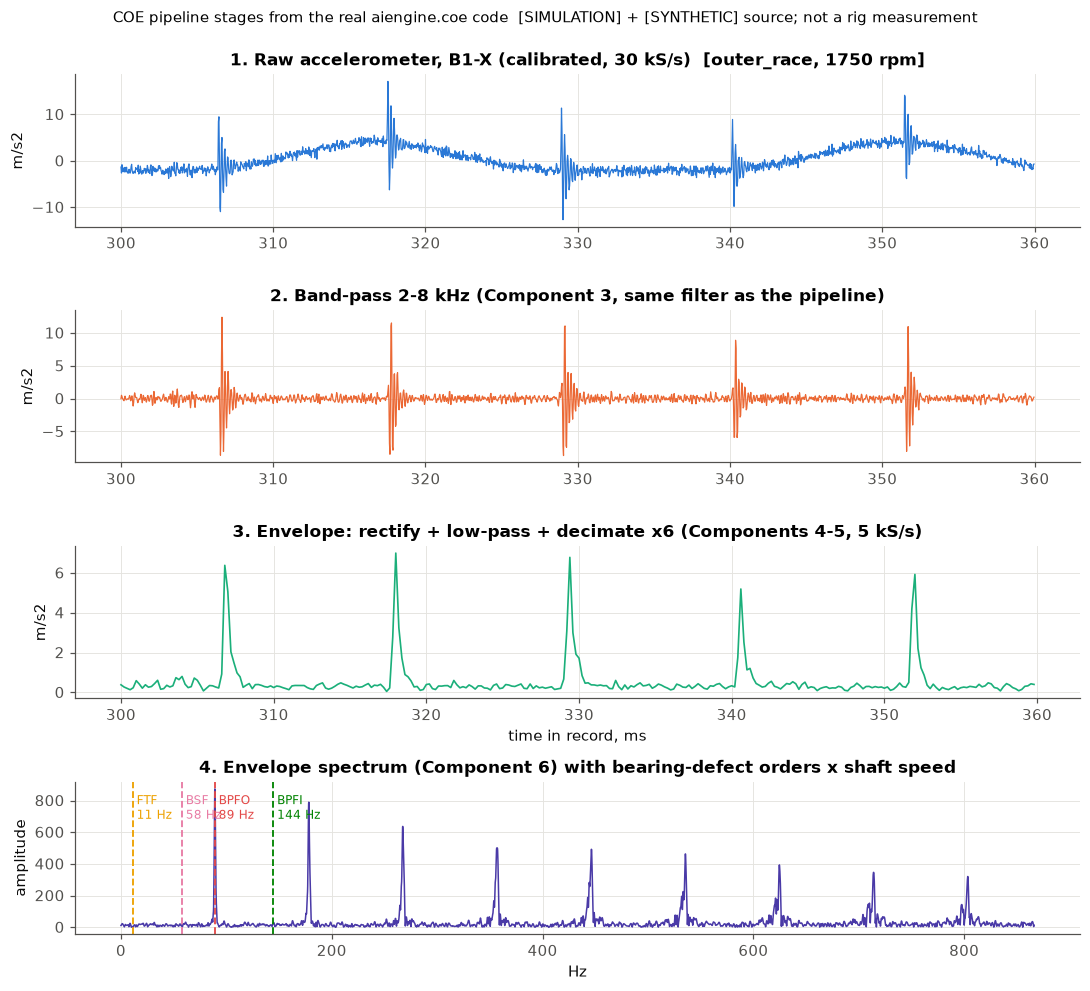

[SIMULATION]+[SYNTHETIC] picture + data; stored copy: evidence\up2_figures\coe_pipeline_stages.png


In [11]:
try:
    fig = U.coe_stage_figure(FIG / "coe_pipeline_stages.png"); plt.show()
    print("[SIMULATION]+[SYNTHETIC] picture + data; stored copy:", (FIG / "coe_pipeline_stages.png").relative_to(U.REPO))
except Exception as e:
    print("stage figure failed:", type(e).__name__, e)

In [12]:
# C6 of the spec sheet is the ENCLOSURE (ME). The wireless-link reliability constraint COE simulated is a PROPOSED extra, not one of the 18; shown for information only.
c6 = (coe_st or {}).get("C6")
if c6: print("[SIMULATION, ASSUMED loss rates] proposed link-reliability constraint: end-to-end window loss", c6["window_loss_pct"]["end_to_end"], "% (limit 1 %) ->", c6["verdict"], "| source", U.stamp(coe_p))

[SIMULATION, ASSUMED loss rates] proposed link-reliability constraint: end-to-end window loss 0.133 % (limit 1 %) -> MET under stated loss assumptions [SIMULATION] | source coe_verification.json (file mtime 2026-10-24 04:38)


## 4. C4 (no cloud) and C5 (LAN-only dashboard), live

In [13]:
C4 = U.c4_no_network_live()
print(C4)
if C4["status"] == "ok" and C4["guard_blocks_dns"] and C4["ran"]:
    U.record("C4", status="MET [MEASURED host]", value=f"{C4['windows']} windows classified + RUL with all network calls blocked (DNS lookup raised)", target="no cloud reliance", rank=7, firm=True, achievable=9,
             note="COE-assigned in the sheet; counted for ICS by team decision 2026-10-05. DAQ+DSP part = simulated COE pipeline running locally (S4-S6)", step="Repeat with the real node and a physically disconnected uplink",
             prov="[MEASURED host] (network-denied Python run)", source="live: up2_helpers.c4_no_network_live")
else:
    U.record("C4", status="NOT EVIDENCED (live check failed)", rank=0, note=str(C4))

{'status': 'ok', 'guard_blocks_dns': True, 'windows': 120, 'ran': True}


In [14]:
C5 = U.c5_live()
print(C5)
if C5["status"] == "ok" and C5["failed"] == 0 and C5["passed"] >= 19:
    U.record("C5", status="MET [MEASURED host]", value=f"{C5['passed']}/{C5['total']} LanOnlyTests+UdpLanGuardTests pass (public HTTP clients 403, public UDP senders dropped)", target="LAN only", rank=9, firm=True, achievable=9,
             note="guard unit tests + Kestrel bind; the network-denied run covers the Python inference path, not the C# backend", step="Show a phone on the room Wi-Fi reaching the dashboard and a non-private client refused", prov="[MEASURED host]", source="live: dotnet test tests/DigitalTwin.Backend.Tests")
elif C5["status"] == "ok":
    U.record("C5", status="NOT MET (tests failing)", value=str(C5), rank=9)
else:
    U.record("C5", status="NOT EVIDENCED (dotnet test unavailable)", rank=0, note=str(C5), step="install .NET SDK / fix build")

{'status': 'ok', 'passed': 19, 'failed': 0, 'total': 19, 'elapsed_s': 15.7}


## 5. S9 (dashboard >= 10 Hz) and IS1 (< 500 ms), live against the real backend with the v3b contract
The backend is started from its Release build with `--Backend:ModelContractPath=model_contract_v3b.json` and the `up2` replay source ([SYNTHETIC] stream); the .NET `DemoMeasure` client stands in for the browser (Blazor render time not included). Same flags as `scripts/run-up2-demo.ps1`.

In [15]:
BLD = U.dotnet_ready(); print("build:", BLD)
S9 = U.s9_live(20) if BLD["status"] == "ok" else BLD
print({k: v for k, v in S9.items() if k not in ("metrics", "raw")})
if S9["status"] == "ok":
    st = {s["stage"]: s for s in S9["metrics"]["stages"]}
    display(pd.DataFrame(st).T[["count", "p50Ms", "p95Ms", "maxMs"]].round(2))
    ok = S9["hz"] >= 10 and S9["per_sec_min"] >= 10
    U.record("S9", status="MET [MEASURED host]" if ok else "NOT MET", value=f"{S9['hz']:.1f} Hz client rate; worst 1-s window {S9['per_sec_min']}", target=">= 10 Hz",
             note="CAVEAT: the ~30 Hz is a client-side count of the backend's 50 ms re-broadcast timer; NEW data arrives at the 10 Hz replay rate (the spec minimum). SignalR .NET client, localhost, [SYNTHETIC] stream; browser render not measured (skipped by decision); spec also says physics RUL updated together; approval column still 'No'", rank=6, firm=True, achievable=9,
             step="Open the dashboard in a browser on a second device; a screen recording was not possible here (no ffmpeg/Playwright)", prov="[MEASURED host], [SYNTHETIC] stream", source="live: DemoMeasure rate")
else:
    v = integ.get("s9_hz")
    if v: U.record("S9", status="MET [MEASURED host]" if v >= 10 else "NOT MET", value=f"{v:.1f} Hz (STORED)", target=">= 10 Hz", rank=6, achievable=9, step="live backend cell failed; re-run", prov="[MEASURED host] stored", source=U.stamp(int_p))
    else: U.record("S9", status="NOT EVIDENCED (no live run, no stored value)", rank=0)

build: {'status': 'ok', 'backend_s': 5.4, 'demomeasure_s': 2.5}


{'status': 'ok', 'snapshots': 601, 'seconds': 20.0, 'hz': 30.04, 'gap_p50_ms': 43.9, 'gap_p95_ms': 62.2, 'gap_max_ms': 67.7, 'per_sec_min': 30, 'per_sec_max': 31}


,count,p50Ms,p95Ms,maxMs
broadcast,214,0.0591,0.1564,1.5526
decode,214,0.0028,0.0165,0.1881
features,214,0.0306,0.0963,39.0132
inference,214,3.6362,5.1252,54.3106
nhits_onnx,190,2.5447,3.5508,6.2096
tft_onnx,190,1.0633,1.4382,16.5382
total_ingest_to_broadcast,214,3.787,5.4062,55.9941


In [16]:
I1 = U.is1_live(n=120) if BLD["status"] == "ok" else BLD
if I1["status"] == "ok":
    lg = I1["legs"]; print(I1["report_md"][-1700:])
    s = lg["sum_stm32"]
    U.record("IS1", status="MET [SIMULATION]" if s["max"] < 500 else "NOT MET", value=f"p95 {s['p95']:.1f} ms, max {s['max']:.1f} ms (STM32-pessimistic COE + simulated Wi-Fi 10-60 ms + measured backend)", target="< 500 ms",
             note="Wi-Fi hop is SIMULATED, STM32 leg CALCULATED, browser render not included. Only a Wi-Fi hop of ~380 ms or more would break the budget (sensitivity table below). Rank 9 as a live end-to-end SIMULATION demo (injected Wi-Fi hop, calculated STM32 leg: assumed legs disclosed, so not counted firm)", rank=9, firm=False, achievable=9,
             step="Measure the real ESP32-C6 -> AP -> server hop and the STM32 leg; show the browser update", prov="[MEASURED host] + [SIMULATION] Wi-Fi + [CALCULATED] STM32", source="live: DemoMeasure is1; " + U.stamp(int_p))
else:
    print(I1)
    v = integ.get("is1")
    if v: U.record("IS1", status="MET [SIMULATION]" if v["max"] < 500 else "NOT MET", value=f"p95 {v['p95']:.1f} / max {v['max']:.1f} ms (STORED)", target="< 500 ms", rank=6, achievable=9, step="re-run live cell", prov="[MEASURED host]+[SIMULATION]+[CALCULATED] stored", source=U.stamp(int_p))
    else: U.record("IS1", status="NOT EVIDENCED (no live run, no stored value)", rank=0)

; Blazor WASM render time is NOT included). One monotonic clock. Windows are sent one at a time at 20 Hz. Marker: rpm nudged by <= 0.2 rpm to identify each window's snapshot.

## Measured legs (this PC, Windows host)
| Leg | p50 ms | p95 ms | max ms | Provenance |
|---|---|---|---|---|
| Wi-Fi hop (injected delay realised) | 32.5 | 63.8 | 65.2 | [SIMULATION] assumed 10-60 ms jitter |
| UDP + backend (decode, features, 2x ONNX, SignalR) + client receive | 5.0 | 7.1 | 16.5 | [MEASURED host] localhost; not the target server / Pi 5 |
| Sender window-close -> client receive (two rows above) | 39.0 | 70.2 | 77.8 | [MEASURED host + SIMULATION] |

## Budget including COE processing (t20 -> payload ready), from AI-engine/reports/coe_verification.json
| Stage | p50 ms | p95 ms | max ms | Provenance |
|---|---|---|---|---|
| COE t20 -> payload ready, host PC (Python/NumPy; worst of 1750/3600 rpm) | 5.3 | 6.8 | 9.0 | [MEASURED host], not STM32 |
| COE t20 -> payload ready, STM32 pessimistic (10 cy

### 5b. IS1 sensitivity to the Wi-Fi hop `[CALCULATED]`
No new measurement: the per-window backend leg (from the live IS1 run above, or the stored file) plus the COE STM32-pessimistic leg (28.4 ms, calculated) plus an assumed hop.

In [17]:
try:
    if I1["status"] == "ok":
        bk = I1["legs"]["backend"]
    else:
        bk = None
    coe_leg = 28.4
    if bk is None:
        raise RuntimeError("no backend leg available (IS1 live run failed)")
    tab, brk = U.is1_sensitivity(bk["p95"], bk["max"], coe_leg)
    display(tab.style.hide(axis="index"))
    print(f"[CALCULATED] backend leg p95 {bk['p95']} / max {bk['max']} ms (measured host), COE leg {coe_leg} ms (STM32 pessimistic, calculated). "
          f"The 500 ms budget breaks only if the real Wi-Fi hop exceeds ~{brk:.0f} ms (worst-case backend). Wi-Fi hop itself is NOT measured.")
except Exception as e:
    print("sensitivity unavailable:", e)

Wi-Fi hop assumed,COE leg ms,backend p95 ms,backend max ms,total (p95 backend) ms,total (max backend) ms,< 500 ms
sim 10-60 ms (max),28.400000,7.100000,16.500000,95.500000,104.900000,yes
100 ms,28.400000,7.100000,16.500000,135.500000,144.900000,yes
300 ms,28.400000,7.100000,16.500000,335.500000,344.900000,yes


[CALCULATED] backend leg p95 7.1 / max 16.5 ms (measured host), COE leg 28.4 ms (STM32 pessimistic, calculated). The 500 ms budget breaks only if the real Wi-Fi hop exceeds ~455 ms (worst-case backend). Wi-Fi hop itself is NOT measured.


[picture of the demo; data tables for S9/IS1 are above] dashboard_up2_20261024.png (file mtime 2026-10-24 16:28)


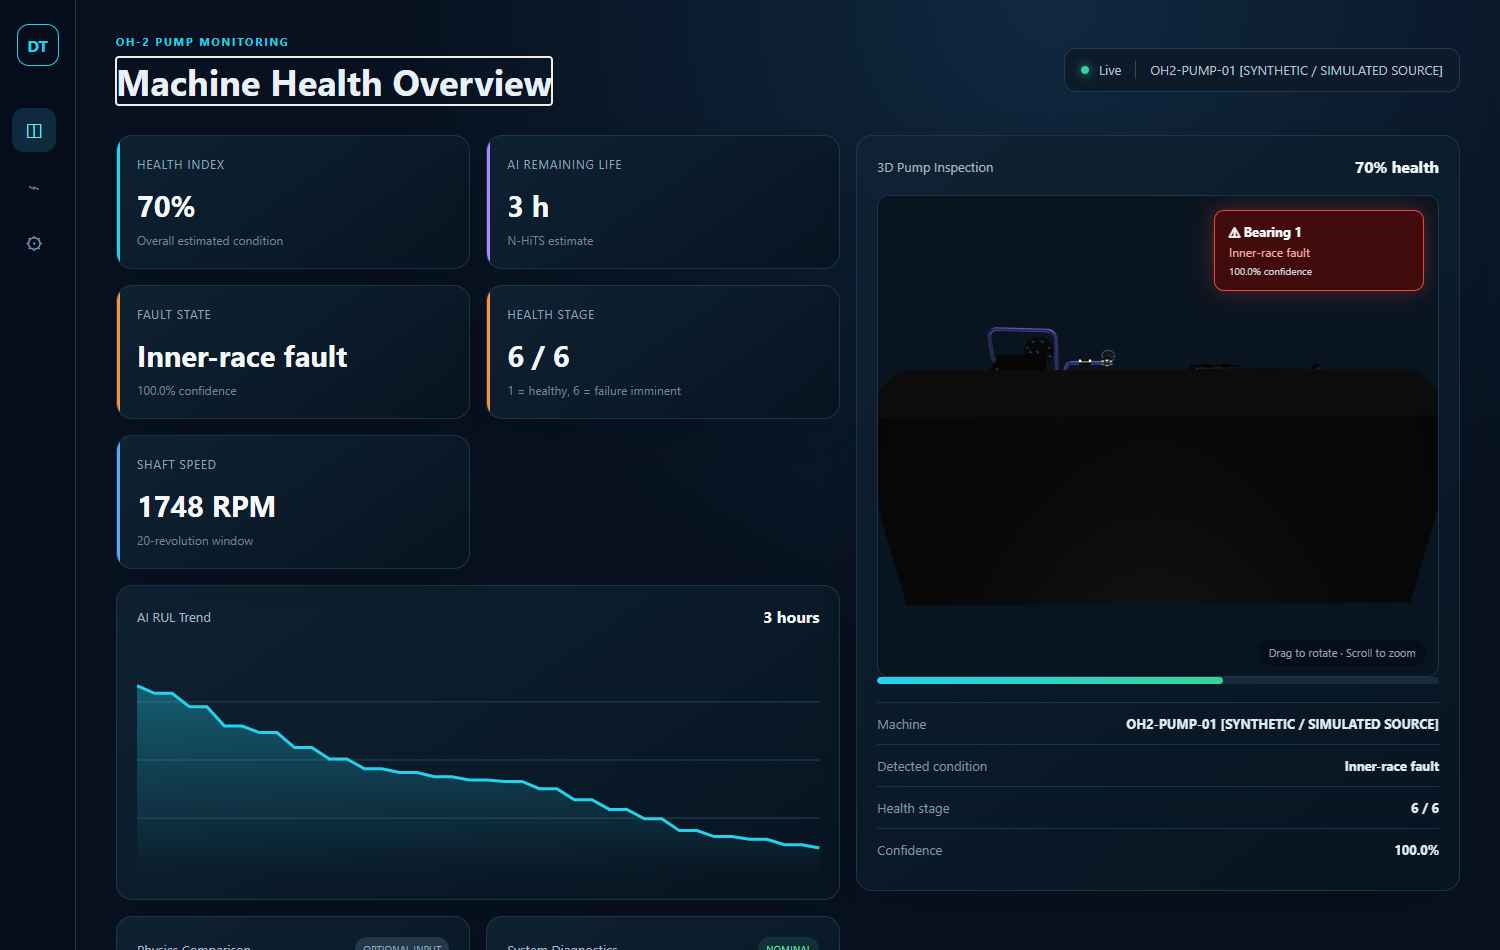

[picture of the demo; data tables for S9/IS1 are above] dashboard_up2_coe_20261025.png (file mtime 2026-10-25 00:43)


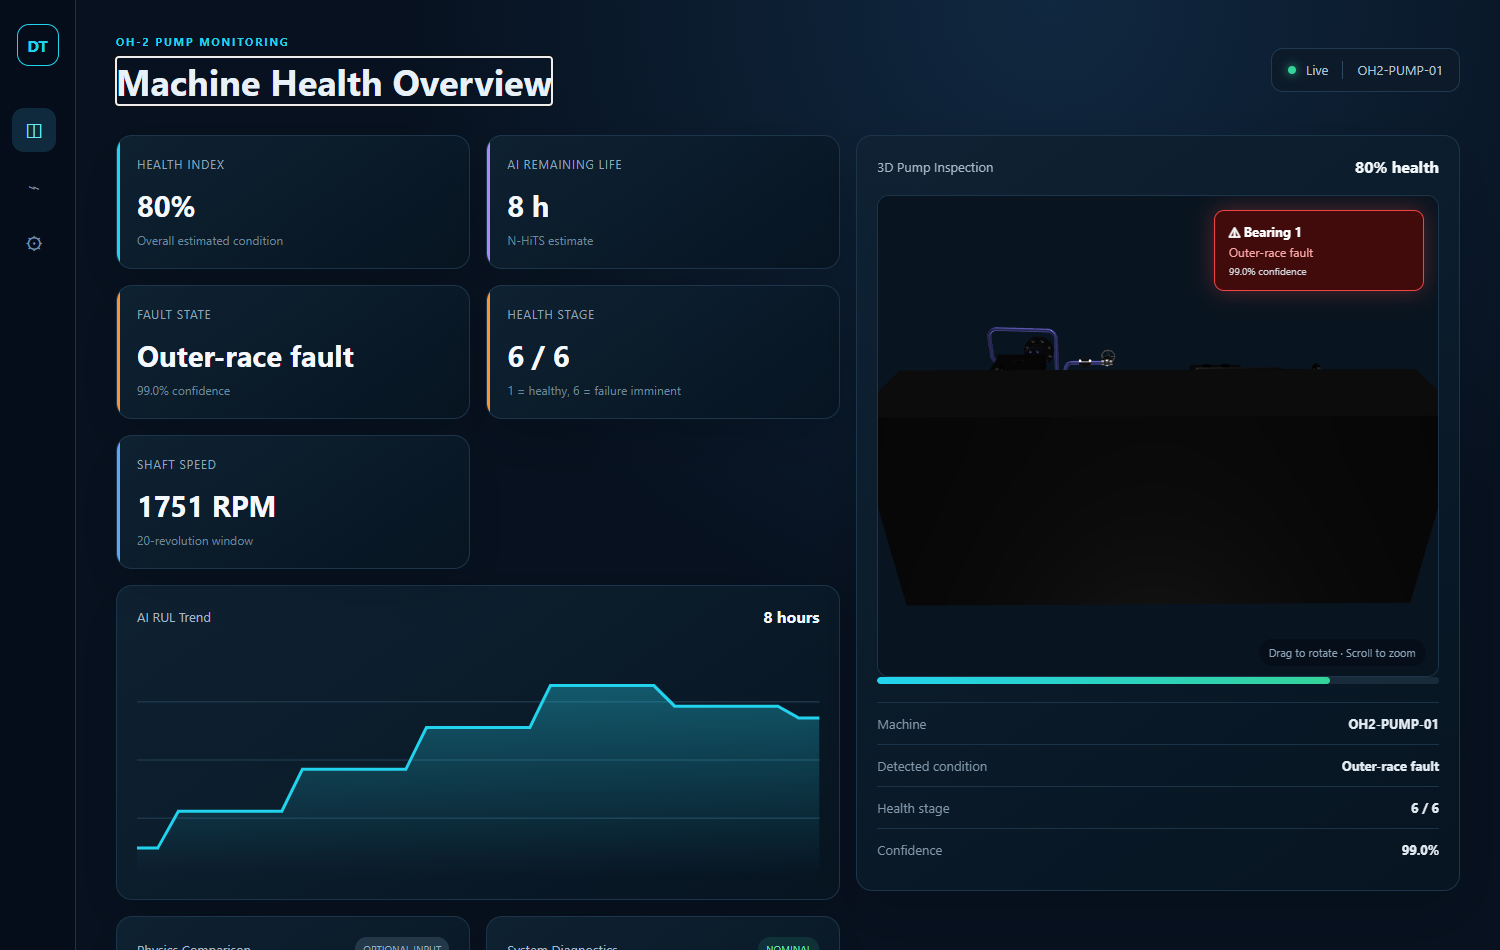

[picture of the demo; data tables for S9/IS1 are above] dashboard_up2_replay_20261025.png (file mtime 2026-10-25 00:45)


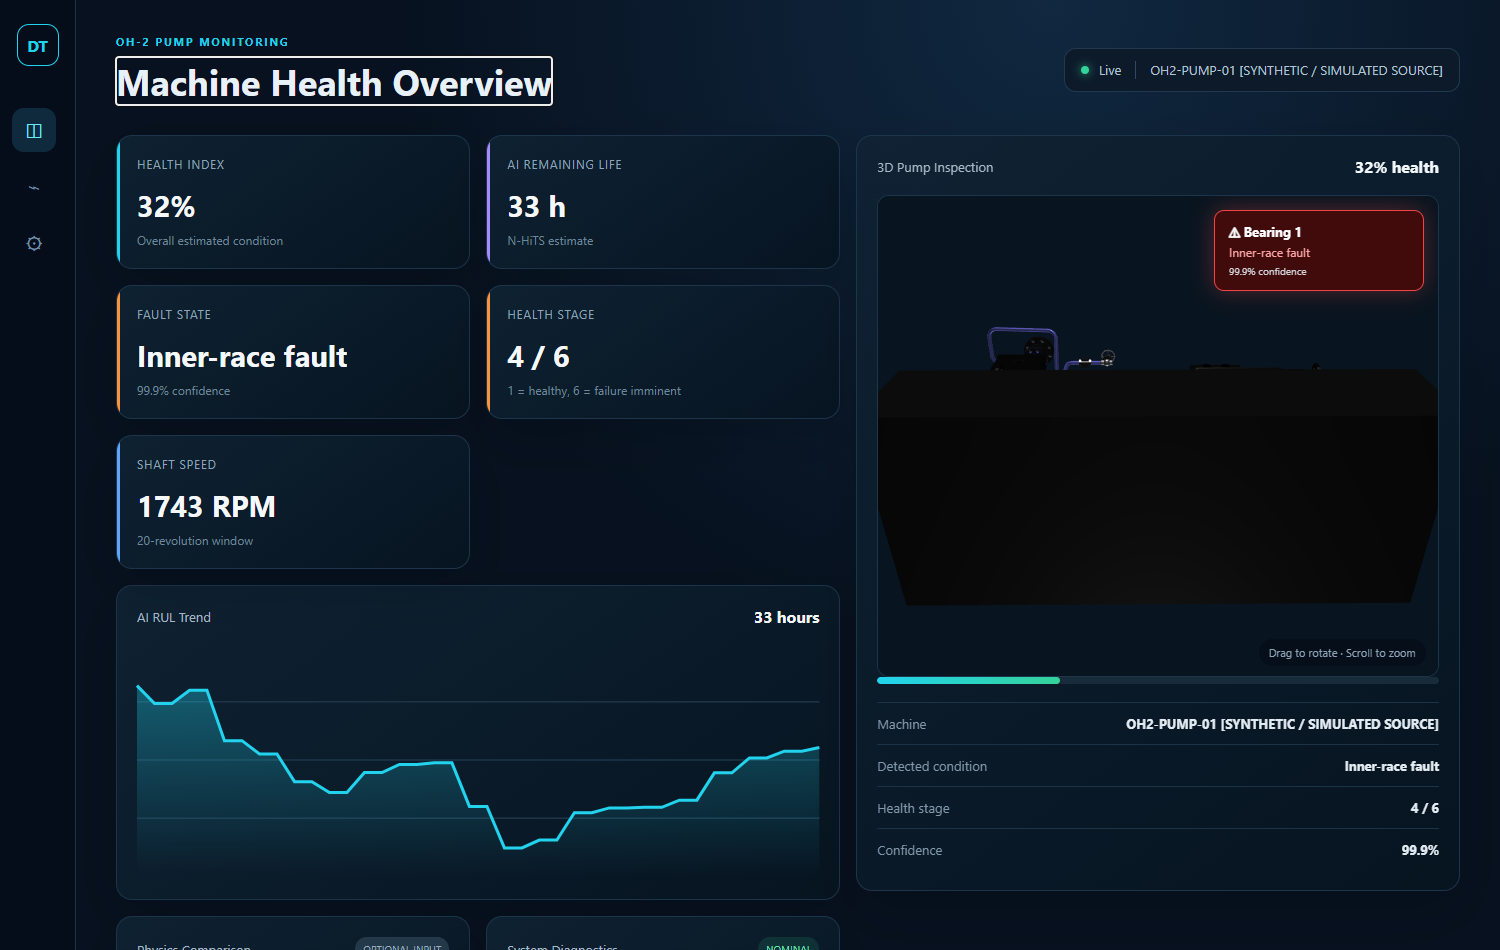

video of the demo: NOT produced. No ffmpeg or Playwright is installed in this environment, so a reliable screen recording was not possible.


In [18]:
dash = sorted(U.EVIDENCE.glob("dashboard_up2_*.png"))
if dash:
    for p in dash[-3:]:
        print("[picture of the demo; data tables for S9/IS1 are above]", U.stamp(p)); display(Image(filename=str(p), width=900))
else:
    print("missing: evidence/dashboard_up2_*.png (dashboard screenshot not on disk yet)")
print("video of the demo: NOT produced. No ffmpeg or Playwright is installed in this environment, so a reliable screen recording was not possible.")

## 6. The demo stream through the deployed engine (picture + data); this is what the dashboard replays

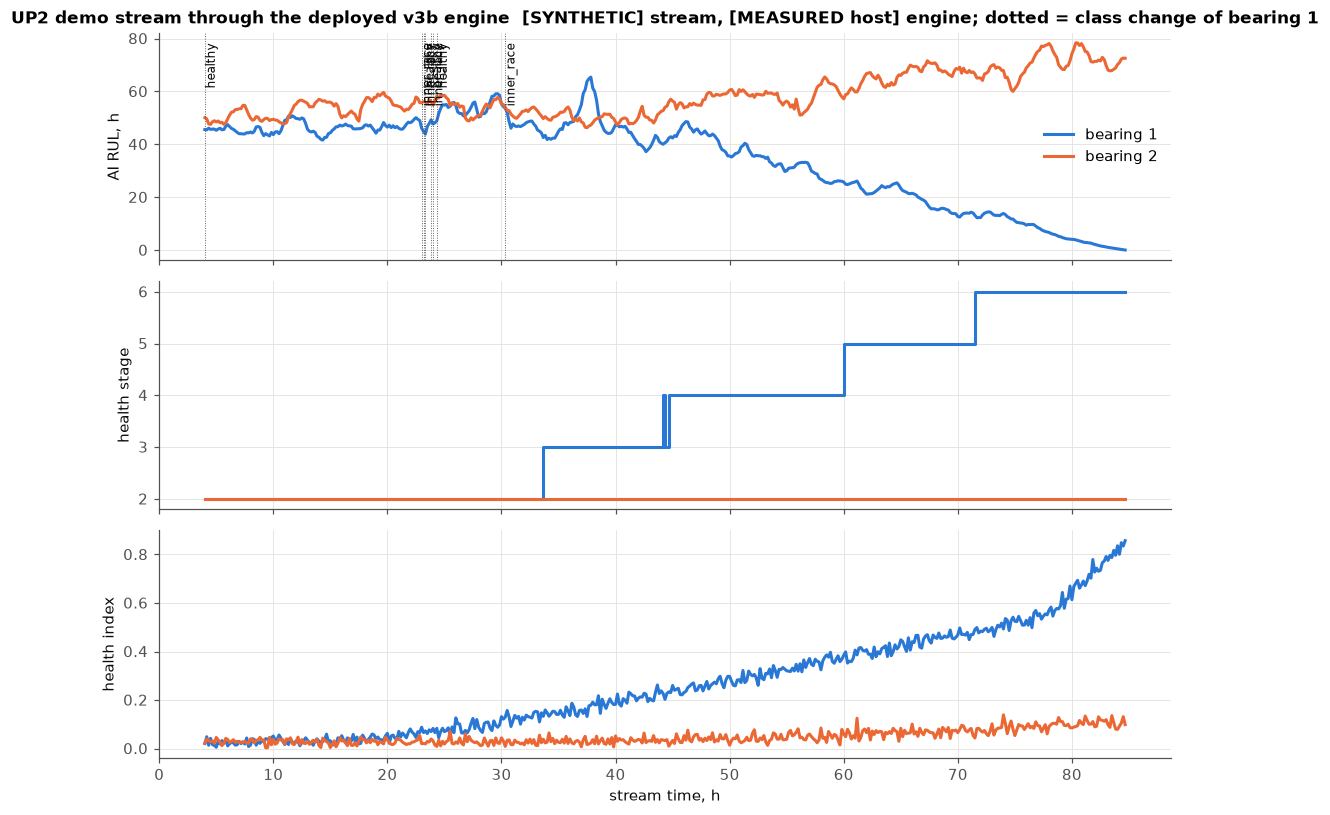

[SYNTHETIC] stream, [MEASURED host] engine: 485 scored windows of bearing 1; classes: {'inner_race': 333, 'healthy': 152} | stage 2 to 6 | engine latency p95 4.15 ms
stored copy: evidence\up2_figures\up2_demo_timeline.png


In [19]:
try:
    TL, fg, meta = U.demo_timeline(FIG / "up2_demo_timeline.png"); plt.show()
    d1 = TL[TL.bearing == 1]
    print(f"[SYNTHETIC] stream, [MEASURED host] engine: {len(d1)} scored windows of bearing 1; classes:", d1.cls.value_counts().to_dict(), "| stage", int(d1.stage.min()), "to", int(d1.stage.max()),
          "| engine latency p95 %.2f ms" % d1.lat_ms.quantile(.95))
    print("stored copy:", (FIG / "up2_demo_timeline.png").relative_to(U.REPO))
except Exception as e:
    print("timeline failed:", type(e).__name__, e)

## 7. IS2 under the ORIGINAL literal wording v1 (history, FAILS; superseded by wording v2 in section 7c)
Stored `[SIMULATION]`+`[SYNTHETIC]` report with command and seed. Re-run: `cd AI-engine; .venv/Scripts/python.exe -m aiengine.up2_residual`. The physics RUL is driven by a stiffness trajectory derived from the same synthetic damage curve (circularity, stated in the report).

In [20]:
if resid:
    h = U.residual_headline(resid, res_p.with_suffix(".md"))
    print("file:", U.stamp(res_p)); print("headline (parsed):", h)
    md_p = res_p.with_suffix(".md")
    if md_p.exists():
        txt = md_p.read_text(encoding="utf-8"); i = txt.find("## Verdict"); print(txt[i:i + 1500])
    mx = h["max"]
    U.record("IS2", status="NOT MET [SIMULATION]", value=(f"v1 literal, test2 tuned-filter, history: max {mx:.1f} % (p95 {h.get('p95', float('nan')):.1f} %, median {h.get('median', float('nan')):.1f} %; windows <=5 %: {h.get('share5', float('nan')):.1f} %)" if isinstance(mx, (int, float)) else "see report"), target="<= 5 %",
             note="best tuned configuration still far above 5 %; floor from the AI RUL error alone is 15 % median. Open physics-role contradiction: ICS doc s2 (physics as AI input vs independent physics RUL compared via residual)", rank=6, achievable=9,
             step="Run `python -m aiengine.up2_residual` live in the demo; a PASS needs an independent physics RUL plus an AI RUL within ~5 % of truth, i.e. a spec-definition decision by team/reviewer",
             prov="[SIMULATION] + [SYNTHETIC]", source=U.stamp(res_p))
else:
    U.record("IS2", status="NOT MET (no report on disk)", rank=0)
    print("missing: reports/up2_residual_*.json")

file: up2_residual_20261024T173626Z.json (file mtime 2026-10-24 20:36)
headline (parsed): {'max': 302.09677262629407, 'p95': 90.78334615905989, 'median': 39.021809367589725, 'share5': 5.264823802489977, 'coverage': 57.5820170109356, 'n': 9478, 'src': 'json sweep.nominal.score.residual'}
## Verdict

| Reading | Value | Target | Verdict |
|---|---|---|---|
| IS2 literal: max per-window residual, stages 1-3, nominal, tuned filter | 302.1 % | <= 5 % | **FAIL** |
| p95 residual (alternative reading) | 90.8 % | <= 5 % | FAIL |
| median / mean residual | 39.0 % / 43.6 % | - | - |
| share of windows with residual <= 5 % | 5.3 % | - | - |
| physics coverage (stage 1-3 windows with a physics RUL) | 57.6 % | - | - |

Metric: `residual = |RUL_physics - RUL_AI| / RUL_AI` per window, hours, faulted bearing of each run-to-failure `test2` run, TRUE stage in {1,2,3}, windows where both RULs exist (n = 9478 windows, 40 runs).  AI predictions: `up2_v3b_gbm_20261024T114647Z.index.json` ([SYNTHETIC] synth_

### 7b. IS2 v1 (literal) with the physics-informed v3c attempt (newest `up2c_spec_check_*` report): NOT MET (history)

`v3c` is a **research artifact, NOT the deployed model** (v3b is deployed; v3c is 9.5 MB and not ported to C#). It feeds a physics prior into the RUL head and was scored once on `synth_v3_test3`.

In [21]:
if UC:
    i2 = UC["is2"]; ab = UC["ablation"]
    rows = []
    for k, lab in (("v3c", "v3c, AI consumes physics (consistency reading)"), ("ablation", "v3c without physics (independent reading)"), ("v3b", "deployed v3b (independent reading)")):
        r = i2[k]["residual"]
        rows.append({"AI": lab, "max %": 100 * r["max"], "p95 %": 100 * r["p95"], "median %": 100 * r["median"], "share <= 5 % ": 100 * r["share_le_5pct"] if "share_le_5pct" in r else 100 * r.get("frac_le_5pct", float("nan")),
                     "coverage %": 100 * i2[k]["coverage"], "physics = prior %": 100 * i2[k]["share_physics_is_prior"], "n windows": r["n"]})
    display(pd.DataFrame(rows).round(1).style.hide(axis="index"))
    print(f"[SYNTHETIC]+[SIMULATION] ablation reading (Sept-3 framing): S7 v3c {ab['S7_v3c']:.2f} % vs without physics {ab['S7_ablation']:.2f} % = {100*ab['relative_improvement_vs_ablation']:.1f} % relative gain (target >= 15 %) -> {ab['verdict']}")
    rv = i2["v3c"]["residual"]; ro = i2["v3b"]["residual"]
    U.record("IS2", status="NOT MET [SIMULATION]",
             value=f"literal max residual: independent {100*ro['max']:.1f} % (p95 {100*ro['p95']:.1f}, median {100*ro['median']:.1f}); v3c consistency {100*rv['max']:.1f} % (p95 {100*rv['p95']:.1f}, median {100*rv['median']:.1f}); ablation reading {100*ab['relative_improvement_vs_ablation']:.1f} % relative S7 gain",
             target="max <= 5 % (or Sept-3 ablation: >= 15 % relative gain)", rank=6, achievable=9,
             note="NOT MET under every reading. v3c is a research artifact (not deployed, not in C#). Physics coverage 100 % only through a physics PRIOR (96.7 % of windows), not through identification. Decision for team/coach: IS2 wording needs renegotiation.",
             step="Team/coach decision on the IS2 definition (e.g. p95/median consistency band or the ablation criterion); rig data for an independent physics estimate",
             prov="[SYNTHETIC] synth_v3_test3 + [SIMULATION] FE twin (assumed geometry)", source=U.stamp(up2c_p) + "; " + U.stamp(res_p))

AI,max %,p95 %,median %,share <= 5 %,coverage %,physics = prior %,n windows
"v3c, AI consumes physics (consistency reading)",245.600000,77.900000,33.400000,9.000000,100.000000,96.700000,16505
v3c without physics (independent reading),243.400000,79.300000,29.500000,9.500000,100.000000,96.700000,16505
deployed v3b (independent reading),244.600000,78.500000,29.300000,9.700000,100.000000,96.700000,16505


[SYNTHETIC]+[SIMULATION] ablation reading (Sept-3 framing): S7 v3c 10.51 % vs without physics 10.88 % = 3.4 % relative gain (target >= 15 %) -> FAIL


**Why IS2 cannot pass in this setup (structural, not a tuning gap).**
- In the simulator the stiffness drops by less than 3 % during stages 1-3, below the identification noise, so the physics side has almost no signal there.
- 3600 rpm windows fail the identification gate (stiffness is weakly observable above the bearing mode); that is why coverage reaches 100 % only through a physics prior (96.7 % of windows use it).
- Both estimators carry their own error against truth (AI median 22 %, physics median 28 % on these windows), so a bound on the **maximum** relative difference of 5 % cannot hold: even a perfect physics RUL would leave a 15 % median residual.

**Decision for team / coach (IS2 wording needs renegotiation; we do not claim it met).** Options: (a) a consistency band on p95 or median instead of the max; (b) the Sept-3 ablation criterion (physics inputs improve S7 by >= 15 % relative; currently 3.4 %); (c) keep the literal spec and record it as not met until rig data exists.

## 7c. IS2 under the REWORDED spec (wording v2): PASS on a fresh set, with a prominent caveat

**Wording v2 (from the coach feedback of 2026-10-25; the v1 text is kept in `Specifications.md`).** The xlsx has **not** been updated yet: the team must paste the text from `Specifications.md` ("Ready-to-paste text for the team xlsx").
Thresholds (0.18 and 0.63 of L_ref) were **frozen on validation sets only** (`synth_v3_val4`, `synth_v3_val2`) and committed (355831c) **before** `synth_v3_test4` was scored once.

> **CAVEAT, READ BEFORE QUOTING THE PASS (tell the coach).**
> - Clause (a) mostly measures **agreement with the twin's rated-life PRIOR**: about 97 % of stage 1-3 windows use the prior, because the stiffness drop is <= 5 % in stages 1-3, below the identification noise (~6 % at 1750 rpm, ~25 % at 3600 rpm). An **exact** AI (RUL_AI = truth) would itself score **18.1 %** on clause (a), i.e. it would FAIL it.
> - The residual as a flag for a bad AI estimate is weak: **AUROC 0.55**. Clause (b) and the wrong-AI controls are the discriminating parts.
> - The data are circular and synthetic (the stiffness trajectory and the accelerometer features come from one damage variable).
> - Wording v2 is **not yet confirmed in the official xlsx**; the team must edit it.
> - On the rig, `L_ref` becomes the ISO 281 rated life, and the prior and the thresholds must be re-fit on rig validation data.

In [22]:
up2d_p = U.newest(U.REPORTS, "up2d_is2_2*.json")
UD = U.load_json(up2d_p)
IR = U.is2_v2_rescore("test4")
if UD:
    print("file:", U.stamp(up2d_p), "| set", UD["meta"]["set"], "hash", UD["meta"]["table_hash"], "| predictions scored once", UD["meta"]["scored_utc"])
    print("WORDING v2:", UD["v2_text"]); print("WORDING v1 (kept, superseded):", UD["v1_text"])
    print("frozen thresholds (validation only):", UD["frozen"], "| validation:", UD.get("validation", {}).get("chosen", {}).get("rule"))
    vv = UD["validation"]["values"]
    print("validation values (fraction of L_ref):", {n: {k: (round(v['MED'], 3), round(v['P95'], 3)) for k, v in d.items()} for n, d in vv.items()})
    b, c = UD["models"]["v3b"], UD["models"]["v3c"]
    tab = pd.DataFrame([
        {"model": "v3b (deployed)", "v2 (a) median of bearing medians": 100 * b["v2"]["MED"], "target a": 18.0, "v2 (b) p95 of bearing p95s": 100 * b["v2"]["P95"], "target b": 63.0, "v2 verdict": b["v2"]["verdict"], "v1 literal max (v1 target 5)": 100 * b["v1"]["max"] if "max" in b["v1"] else None},
        {"model": "v3c (research)", "v2 (a) median of bearing medians": 100 * c["v2"]["MED"], "target a": 18.0, "v2 (b) p95 of bearing p95s": 100 * c["v2"]["P95"], "target b": 63.0, "v2 verdict": c["v2"]["verdict"], "v1 literal max (v1 target 5)": 100 * c["v1"]["max"] if "max" in c["v1"] else None}])
    display(tab.round(1).style.hide(axis="index"))
    print("v1 literal on test3 (history):", {k: f"{100*v:.0f} %" for k, v in UD["history_v1"].items() if isinstance(v, float)}, "-> FAIL under v1 (kept for transparency)")
    fl = UD["floor_perfect_ai"]
    print(f"perfect-AI floor on test4: MED {100*fl['MED']:.1f} %, P95 {100*fl['P95']:.1f} % -> {fl['verdict']} (an exact AI fails clause (a): the caveat above)")
    display(pd.DataFrame(UD["controls"])[["control", "MED", "P95", "verdict"]].assign(MED=lambda d: (100 * d.MED).round(1), P95=lambda d: (100 * d.P95).round(1)))
    print(f"residual as bad-estimate flag (v3b): AUROC {b['flag_auroc']['auroc']:.3f}; physics = prior on {100*b['v2']['share_physics_is_prior']:.1f} % of windows; windows {b['v2']['n_windows']}, bearings {b['v2']['n_bearings']}")
else:
    print("missing: reports/up2d_is2_2*.json")
if IR["status"] == "ok":
    v = IR["models"]["v3b"]["v2"]
    print(f"LIVE re-score of the saved test4 predictions (aiengine.up2d_eval.evaluate, twin physics recomputed, {IR['seconds']} s): v3b MED {100*v['MED']:.2f} %, P95 {100*v['P95']:.2f} % -> {v['verdict']}; controls all FAIL: {all(x['verdict']=='FAIL' for x in IR['controls'])}")
else:
    print(IR)

file: up2d_is2_20261024T225605Z.json (file mtime 2026-10-25 01:56) | set test4 hash 8fa18243ff54183b | predictions scored once 2026-10-24T22:53:44+00:00
WORDING v2: IS2 Physics-AI RUL agreement (wording v2). For the faulted bearing of every run-to-failure run, over every window in true health stages 1-3 after the AI warm-up, the disagreement e = |RUL_physics - RUL_AI| / L_ref between the FE-twin physics RUL and the deployed AI RUL, expressed as a fraction of the bearing's reference (rated) life L_ref at its duty speed, shall satisfy: (a) median over bearings of each bearing's median e <= 0.18 (18 % of L_ref), and (b) 95th percentile over bearings of each bearing's 95th-percentile e <= 0.63 (63 % of L_ref).
WORDING v1 (kept, superseded): Physics-AI residual: max relative error between the FE-identified physics RUL and the AI RUL <=5%, health stage 1->3
frozen thresholds (validation only): {'T_MED': 0.18, 'T_P95': 0.63, 'source': 'reports/up2d_is2_select_20261024T225211Z.json'} | validat

model,v2 (a) median of bearing medians,target a,v2 (b) p95 of bearing p95s,target b,v2 verdict,v1 literal max (v1 target 5)
v3b (deployed),16.300000,18.000000,49.200000,63.000000,PASS,233.400000
v3c (research),18.300000,18.000000,47.800000,63.000000,FAIL,216.100000


v1 literal on test3 (history): {'v3b': '245 %', 'v3c': '246 %', 'ablation': '243 %'} -> FAIL under v1 (kept for transparency)
perfect-AI floor on test4: MED 18.1 %, P95 48.5 % -> FAIL (an exact AI fails clause (a): the caveat above)


,control,MED,P95,verdict
0,AI x 1.5 (optimistic bias),21.6,91.2,FAIL
1,AI x 0.6 (pessimistic bias),29.4,60.3,FAIL
2,AI + 0.3 L_ref,23.0,79.1,FAIL
3,AI time-reversed within bearing,17.8,66.2,FAIL
4,AI = 0.5 L_ref constant,18.5,42.7,FAIL
5,"AI = truth x lognormal(0, 0.5) noise",25.7,172.4,FAIL


residual as bad-estimate flag (v3b): AUROC 0.550; physics = prior on 97.4 % of windows; windows 15863, bearings 80
LIVE re-score of the saved test4 predictions (aiengine.up2d_eval.evaluate, twin physics recomputed, 25.1 s): v3b MED 16.27 %, P95 49.24 % -> PASS; controls all FAIL: True


In [23]:
LS = U.is2_live_subset(step=4)
if LS["status"] == "ok":
    v = LS["v2"]
    print(f"LIVE subset: deployed v3b ONNX engine run on {LS['n_bearings']} faulted bearings of test4 against the twin physics RUL ({LS['seconds']} s): MED {100*v['MED']:.1f} % (<= 18), P95 {100*v['P95']:.1f} % (<= 63) -> {v['verdict']}")
else:
    print(LS)
ok_v2 = bool(UD) and UD["models"]["v3b"]["v2"]["verdict"] == "PASS" and IR["status"] == "ok" and IR["models"]["v3b"]["v2"]["verdict"] == "PASS" and all(x["verdict"] == "FAIL" for x in IR["controls"])
sub_ok = LS["status"] == "ok" and LS["v2"]["verdict"] == "PASS"
if UD:
    b = UD["models"]["v3b"]["v2"]
    U.record("IS2", status="MET [SYNTHETIC]+[SIMULATION] under wording v2 (pending team/xlsx confirmation)" if ok_v2 else "NOT MET [SIMULATION]",
             value=f"v2: median {100*b['MED']:.1f} % (<=18), p95 {100*b['P95']:.1f} % (<=63) of L_ref; v1 literal max {100*UD['models']['v3b']['v1']['max']:.0f} % (FAIL, history); v3c research median {100*UD['models']['v3c']['v2']['MED']:.1f} % FAIL",
             target="v2: median <= 18 %, p95 <= 63 % of L_ref",
             note="CAVEAT: clause (a) mostly measures agreement with the twin's rated-life prior (~97 % of windows); an exact AI scores 18.1 % on (a) and would FAIL it; residual-as-flag AUROC 0.55; circular synthetic data; wording v2 not yet in the official xlsx; on the rig L_ref = ISO 281 rated life and prior/thresholds must be re-fit. Thresholds frozen on validation before test4 (scored once); six wrong-AI controls all FAIL.",
             rank=9 if sub_ok else 6, firm=False, achievable=9, deployed="deployed v3b heads (verdict); v3c research only",
             specnamed="v1 literal (max <= 5 %): v3b 233 %, v3c 216 % FAIL",
             step="Team pastes wording v2 into the xlsx and tells the coach the clause-(a) limitation; on the rig re-fit L_ref (ISO 281), the prior and the thresholds",
             prov="[SYNTHETIC] synth_v3_test4 + [SIMULATION] FE twin (assumed geometry)", source=U.stamp(up2d_p) + "; IS2 rank: " + ("9 for the live subset run (deployed engine + twin), 6 for the full 80-bearing re-score of saved AI predictions" if sub_ok else "6 (saved predictions re-scored)"))

LIVE subset: deployed v3b ONNX engine run on 20 faulted bearings of test4 against the twin physics RUL (49.5 s): MED 14.8 % (<= 18), P95 51.8 % (<= 63) -> PASS


## 8. Items whose evidence the owners will supply (ME-owned, plus COE electrical C2). C3 was excluded by the reviewer.

In [24]:
NEED = {
 "C1": ("ME", "Target-machine envelope: datasheet table of the Goulds 3196 STi/MTi HP and rpm limits, CAD of the sensor mounting on the housing, a vibration-envelope check (<=10 mm/s RMS housing). [CITED] datasheet + CAD = Rank 3; sensor mounted on a pump/rig = Rank 9."),
 "C2": ("COE", "Power-tree schematic or calculation: mains adapter -> SELV <=50 V DC; IEPE 24 V / 4 mA constant-current source over coax with AC coupling into the AD7606 range; ideally a bench photo with a meter reading."),
 "C6": ("ME", "Material datasheets (UV-stabilized ABS/PETG grade) and the enclosure photo or CAD with the material callout."),
 "S1": ("ME", "Accelerometer datasheet (100 mV/g, +-50 g, flat 2-10 kHz) plus the purchase record; best: the 4 sensors on a shaker/pump with a measured sensitivity."),
 "S2": ("ME", "FE beam model: stiffness identification error <= 10 % against a KNOWN-stiffness reference. A repo precursor exists ([SIMULATION], inverse crime) and does not meet the literal spec, so it is not counted. ME must run the reference case."),
 "S3": ("ME", "IP54 evidence for the enclosure (IEC 60529) plus 85 C / UV material data; the reviewer flagged it as a duplicate of C6."),
}
rows = []
for k, (own, what) in NEED.items():
    s2 = U.s2_stored() if k == "S2" else None
    pre = "-"
    if s2 and s2["status"] == "ok":
        pre = f"precursor, NOT counted: 1750 rpm noisy mean err {s2['mean_1750']:.1f} %, p95 {s2['p95_1750']:.1f} %, max {s2['max_1750']:.1f} %; 3600 rpm mean {s2['mean_3600']:.1f} % [SIMULATION]"
    U.record(k, status="NOT EVIDENCED HERE - evidence to be supplied by owner (" + own + ")", value=pre, target="see Specifications.md", note=what, rank=0, achievable="3-9 depending on the owner's artifact", step=what, prov="-",
             source="-" if not s2 or s2["status"] != "ok" else s2.get("file", "-"))
    rows.append({"ID": k, "Owner": own, "Needed to be counted": what})
display(pd.DataFrame(rows).style.hide(axis="index"))

ID,Owner,Needed to be counted
C1,ME,"Target-machine envelope: datasheet table of the Goulds 3196 STi/MTi HP and rpm limits, CAD of the sensor mounting on the housing, a vibration-envelope check (<=10 mm/s RMS housing). [CITED] datasheet + CAD = Rank 3; sensor mounted on a pump/rig = Rank 9."
C2,COE,Power-tree schematic or calculation: mains adapter -> SELV <=50 V DC; IEPE 24 V / 4 mA constant-current source over coax with AC coupling into the AD7606 range; ideally a bench photo with a meter reading.
C6,ME,Material datasheets (UV-stabilized ABS/PETG grade) and the enclosure photo or CAD with the material callout.
S1,ME,"Accelerometer datasheet (100 mV/g, +-50 g, flat 2-10 kHz) plus the purchase record; best: the 4 sensors on a shaker/pump with a measured sensitivity."
S2,ME,"FE beam model: stiffness identification error <= 10 % against a KNOWN-stiffness reference. A repo precursor exists ([SIMULATION], inverse crime) and does not meet the literal spec, so it is not counted. ME must run the reference case."
S3,ME,IP54 evidence for the enclosure (IEC 60529) plus 85 C / UV material data; the reviewer flagged it as a duplicate of C6.


## 8b. COE-integration readiness: the domain gap and its adaptation (supporting evidence for COE1-3 and the hardware-day swap)

**What this is.** The deployed v3b classifier was trained on payload-level synthetic features. The COE pipeline (C1-C9, the code that will become STM32 firmware) produces its own features from raw samples, so the models were tested on **raw samples from the COE rig simulator through the real causal `CoePipeline`**
(dataset `synth_coe`, 420 runs, split by run; the 106-run COE-test was scored once). `[SIMULATION]` + `[SYNTHETIC]`: simulator amplitudes and the partner-bearing transmission gain are invented, nothing here is a rig measurement or validates hardware.
The cell below re-scores the **saved** COE-test predictions with the logic of `python -m aiengine.coe_adapt_eval` (it does not retrain or write a new report). This does **not** add a MET item or change any rank in the master table; it is readiness evidence for S4-S6 and the hardware-day swap.

In [25]:
CA = U.coe_adapt_rescore()
if CA["status"] == "ok":
    print(f"[SIMULATION]+[SYNTHETIC] saved COE-test predictions: {CA['index']} (scored once {CA['scored_utc']}); selected: {CA['selected']}; COE-test runs: {CA['n_runs_test']}, bearing-windows: {CA['windows']}")
    display(CA["table"].round(3).style.hide(axis="index"))
    sm = CA["sel_metrics"]
    print(f"Domain-gap finding: deployed v3b on COE-pipeline windows has macro-F1 {CA['table'].iloc[0]['macro-F1']:.3f} and flags the healthy partner bearing in {CA['table'].iloc[0]['B2 false-fault %']:.1f} % of windows (bearing 2).")
    if sm: print(f"Selected (classifier retrained on synth_v3 + COE-train, COE weight 0.6, + cross-bearing gate tau {CA['selected']['gate_tau']}): macro-F1 {sm['classification']['macro_f1']:.3f}, B2 false-fault {100*sm['b2_transmitted_false_fault_rate']:.1f} %, B1 {100*sm['b1_transmitted_false_fault_rate']:.1f} %, missed-fault {100*sm['missed_fault_rate']:.1f} %, cage F1 {sm['classification']['per_class_f1']['cage']:.2f}.")
    print(f"Stage/RUL heads on COE features: healthy bearings at raw stage >= 2 in {100*CA['rul_diag']['healthy_stage_raw_ge2_rate']:.0f} % of {CA['rul_diag']['healthy_windows']} windows -> NOT reliable on COE features (needs COE run-to-failure data).")
else:
    print(CA)

[SIMULATION]+[SYNTHETIC] saved COE-test predictions: coe_adapt_test_20261024T213231Z.index.json (scored once 2026-10-24T21:33:07+00:00); selected: {'candidate': 'mix_w0.6', 'gate_tau': 0.6, 'gate_signal': 'family'}; COE-test runs: 106, bearing-windows: 14840


classifier,macro-F1,B2 false-fault %,B1 false-fault %,both-healthy false-fault %,missed-fault %,wrong-class %,F1 cage
v3b as deployed,0.584000,82.051000,74.652000,0.075000,2.175000,28.617000,0.242000
"adapted, no gate (ablation: retrain alone)",0.777000,52.962000,39.487000,0.000000,15.408000,3.800000,0.792000
deployed + gate (ablation: gate alone),0.725000,4.421000,2.637000,0.037000,13.897000,19.528000,0.246000
SELECTED: adapted + gate,0.875000,0.619000,0.000000,0.000000,22.825000,0.160000,0.828000


Domain-gap finding: deployed v3b on COE-pipeline windows has macro-F1 0.584 and flags the healthy partner bearing in 82.1 % of windows (bearing 2).
Selected (classifier retrained on synth_v3 + COE-train, COE weight 0.6, + cross-bearing gate tau 0.6): macro-F1 0.875, B2 false-fault 0.6 %, B1 0.0 %, missed-fault 22.8 %, cage F1 0.83.
Stage/RUL heads on COE features: healthy bearings at raw stage >= 2 in 100 % of 5172 windows -> NOT reliable on COE features (needs COE run-to-failure data).


**Limitations (stated plainly).** (1) The missed-fault rate rises to 22.8 % because the gate trades recall at low severity (<= 0.2) for removing the false alarms on the partner bearing. (2) The stage and RUL heads are unreliable on COE features and the COE runs are not run-to-failure, so no RUL or stage truth exists there. (3) The simulator's partner-transmission gain is invented, so `tau` is a placeholder. (4) None of this validates real hardware.

**What to re-fit on the first rig data (hardware day):** the gate threshold `tau` (commissioning data with a known-healthy partner), the stage cut, and the classifier itself with real seeded faults; then re-score S7/IS3 on rig windows. The adapted classifier and contract are `models/v3b_coe_cls.onnx` / `model_contract_v3b_coe.json` for COE-pipeline sources (the deployed v3b contract is unchanged).

## 9. Tests (live)

In [26]:
T = {"coe (tests/coe)": U.pytest_live(["tests/coe"]), "up2 + twin_up2": U.pytest_live(["tests/up2", "tests/twin_up2"])}
for k, v in T.items(): print(k, v if v["status"] != "ok" else (v["tail"], f"{v['seconds']} s"))

coe (tests/coe) ('24 passed in 2.55s', '3.4 s')
up2 + twin_up2 ('29 passed in 55.40s', '56.7 s')


## 10. MASTER TABLE: the 17 counted items (C3 excluded by the reviewer)

In [27]:
M = U.master_frame()
M["Rank achieved"] = M["Rank achieved"].astype(str)
pd.set_option("display.max_colwidth", 90)
display(M.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

ID,Item,Owner dept,PPR status (old),UP2 status,Measured,Target,Verdict / note,Model actually deployed,"Spec-named model (N-HiTS/TFT), same data",Firm?,Rank achieved,Rank achievable,Step that raises it,Provenance,Source
C1,"OH-2 (API 610) pumps, Goulds 3196 STi+MTi class: drivers <=40/~122 HP, 1750/3500 rpm, housing <=10 mm/s RMS",ME,NOT EVIDENCED,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),-,see Specifications.md,"Target-machine envelope: datasheet table of the Goulds 3196 STi/MTi HP and rpm limits, CAD of the sensor mounting on the housing, a vibration-envelope check (<=10 mm/s RMS housing). [CITED] datasheet + CAD = Rank 3; sensor mounted on a pump/rig = Rank 9.",-,-,no,0,3-9 depending on the owner's artifact,"Target-machine envelope: datasheet table of the Goulds 3196 STi/MTi HP and rpm limits, CAD of the sensor mounting on the housing, a vibration-envelope check (<=10 mm/s RMS housing). [CITED] datasheet + CAD = Rank 3; sensor mounted on a pump/rig = Rank 9.",-,-
C2,"Mains-powered node; SELV (<=50 V DC) IEPE excitation 24 V/4 mA over coax, AC-coupled to ADC range",COE,NOT EVIDENCED,NOT EVIDENCED HERE - evidence to be supplied by owner (COE),-,see Specifications.md,Power-tree schematic or calculation: mains adapter -> SELV <=50 V DC; IEPE 24 V / 4 mA constant-current source over coax with AC coupling into the AD7606 range; ideally a bench photo with a meter reading.,-,-,no,0,3-9 depending on the owner's artifact,Power-tree schematic or calculation: mains adapter -> SELV <=50 V DC; IEPE 24 V / 4 mA constant-current source over coax with AC coupling into the AD7606 range; ideally a bench photo with a meter reading.,-,-
C4,"All real-time DAQ and signal processing run on local hardware, no cloud reliance",COE (counted for ICS),MET,MET [MEASURED host],120 windows classified + RUL with all network calls blocked (DNS lookup raised),no cloud reliance,COE-assigned in the sheet; counted for ICS by team decision 2026-10-05. DAQ+DSP part = simulated COE pipeline running locally (S4-S6),-,-,yes,7,9,Repeat with the real node and a physically disconnected uplink,[MEASURED host] (network-denied Python run),live: up2_helpers.c4_no_network_live
C5,Dashboard accessible only on the local network; no external/cloud exposure of vibration data,ICS,MET,MET [MEASURED host],"19/19 LanOnlyTests+UdpLanGuardTests pass (public HTTP clients 403, public UDP senders dropped)",LAN only,"guard unit tests + Kestrel bind; the network-denied run covers the Python inference path, not the C# backend",-,-,yes,9,9,Show a phone on the room Wi-Fi reaching the dashboard and a non-private client refused,[MEASURED host],live: dotnet test tests/DigitalTwin.Backend.Tests
C6,Enclosure from UV-stabilized weather-resistant polymer (ABS/PETG),ME,NOT EVIDENCED,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),-,see Specifications.md,Material datasheets (UV-stabilized ABS/PETG grade) and the enclosure photo or CAD with the material callout.,-,-,no,0,3-9 depending on the owner's artifact,Material datasheets (UV-stabilized ABS/PETG grade) and the enclosure photo or CAD with the material callout.,-,-
S1,"2x biaxial IEPE sets (4 ch): 100 mV/g, +-50 g, flat 2-10 kHz (off-the-shelf)",ME,NOT EVIDENCED,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),-,see Specifications.md,"Accelerometer datasheet (100 mV/g, +-50 g, flat 2-10 kHz) plus the purchase record; best: the 4 sensors on a shaker/pump with a measured sensitivity.",-,-,no,0,3-9 depending on the owner's artifact,"Accelerometer datasheet (100 mV/g, +-50 g, flat 2-10 kHz) plus the purchase record; best: the 4 sensors on a shaker/pump with a measured sensitivity.",-,-
S2,"FE digital twin identifies bearing stiffness K, <=10 % error vs known-stiffness reference",ME,NOT EVIDENCED,NOT EVIDENCED HERE - evidence to be supplied by owner (ME),"precursor, NOT counted: 1750 rpm noisy mean err 6.4 %, p95 13.6 %, max 15.5 %; 3600 rpm mean 24.2 % [SIMULATION]",see Specifications.md,"FE beam model: stiffness id

In [28]:
cnt = U.verdict_counts(M)
print("C3 (BOM cost): EXCLUDED by the reviewer, not counted.")
print("(IS2 v1 literal values by set: test2 tuned filter 302 % [section 7]; test4 deployed v3b 233 % [section 7c].)")
print("Counts as labelled:", {k: cnt[k] for k in ("MET", "PARTIAL", "NOT MET", "NOT EVIDENCED")}, "of", cnt["total"])
print(f"HONEST TALLY: firm (rank >= 6, no assumed/calculated leg) = {cnt['firm']}  |  met at design level only (rank < 6 or an assumed/simulated leg) = {cnt['design_level']}  |  total counted MET = {cnt['MET']}")
print("   firm :", list(M[(M['UP2 status'].str.startswith('MET')) & (M['Firm?'] == 'yes')].ID))
print("   design level:", list(M[(M['UP2 status'].str.startswith('MET')) & (M['Firm?'] != 'yes')].ID))
print(f"MET share: {cnt['pct_met']:.1f} %   |   rubric needs MORE THAN 75 % (>= {cnt['bar']} of {cnt['total']}): {'YES' if cnt['gt75'] else 'NO'}")
cons = M.copy(); cons.loc[cons.ID == "IS1", "UP2 status"] = "PARTIAL (Wi-Fi hop simulated)"
cons.loc[cons.ID == "IS2", "UP2 status"] = "PARTIAL (wording v2 unconfirmed)"; c2 = U.verdict_counts(cons); print(f"Conservative reading (IS1 -> PARTIAL because the Wi-Fi hop is simulated, and IS2 -> PARTIAL because wording v2 is not yet confirmed by the team/xlsx): MET {c2['MET']} of 17 = {c2['pct_met']:.1f} %")
need = max(0, cnt["bar"] - cnt["MET"]); print(f"Items still needed for >= {cnt['bar']}: {need}. Candidates: C1, C2, C6, S1, S2, S3 (NOT EVIDENCED; each needs the owner's artifact, section 8).")
s = M.set_index("ID")["UP2 status"]
ics = {"constraint C5": s["C5"], "spec S7": s["S7"], "spec S8": s["S8"]}
ok = all(v.startswith("MET") for v in ics.values())
print("ICS department (1 constraint + 2 specs):", ics, "->", "ALL MET" if ok else "NOT ALL MET")
print("MODEL CHANGE APPROVED (N-HiTS/TFT -> gradient-boosted heads). Original spec-named models kept for transparency: N-HiTS S7 %.1f %%, TFT stage max error %s, TFT p95 %.2f ms." % (SN.get("S7", float("nan")), SN.get("stage_max"), SN.get("tft_p95", float("nan"))))
print("Other ICS-related items: S9", s["S9"], "| IS1", s["IS1"], "| IS3", s["IS3"], "| IS2", s["IS2"])
print("Old (PPR) MET:", [i for i, _, _, p in U.ITEMS if p == "MET"], "-> now MET:", list(s[s.str.startswith('MET')].index))
print(f"notebook run time: {time.time()-T_START:.0f} s")

C3 (BOM cost): EXCLUDED by the reviewer, not counted.
(IS2 v1 literal values by set: test2 tuned filter 302 % [section 7]; test4 deployed v3b 233 % [section 7c].)
Counts as labelled: {'MET': 11, 'PARTIAL': 0, 'NOT MET': 0, 'NOT EVIDENCED': 6} of 17
HONEST TALLY: firm (rank >= 6, no assumed/calculated leg) = 7  |  met at design level only (rank < 6 or an assumed/simulated leg) = 4  |  total counted MET = 11
   firm : ['C4', 'C5', 'S6', 'S7', 'S8', 'S9', 'IS3']
   design level: ['S4', 'S5', 'IS1', 'IS2']
MET share: 64.7 %   |   rubric needs MORE THAN 75 % (>= 13 of 17): NO
Conservative reading (IS1 -> PARTIAL because the Wi-Fi hop is simulated, and IS2 -> PARTIAL because wording v2 is not yet confirmed by the team/xlsx): MET 9 of 17 = 52.9 %
Items still needed for >= 13: 2. Candidates: C1, C2, C6, S1, S2, S3 (NOT EVIDENCED; each needs the owner's artifact, section 8).
ICS department (1 constraint + 2 specs): {'constraint C5': 'MET [MEASURED host]', 'spec S7': 'MET [SYNTHETIC]', 'spec S8'

In [29]:
tt = pd.DataFrame([{"suite": k, **{x: v.get(x) for x in ("status", "passed", "failed", "tail")}} for k, v in T.items()]); display(tt)
M.to_csv(FIG / "up2_master_table.csv", index=False)
print("master table saved:", (FIG / "up2_master_table.csv").relative_to(U.REPO))

,suite,status,passed,failed,tail
0,coe (tests/coe),ok,24,0,24 passed in 2.55s
1,up2 + twin_up2,ok,29,0,29 passed in 55.40s


master table saved: evidence\up2_figures\up2_master_table.csv
